# Experimentos con XGBoost: pronóstico hora a hora del precio de bolsa

Este notebook prueba XGBoost sobre el panel horario (`panel_horario_modelo.csv.gz`)
con tres cantidades de datos y nueve horizontes, y lo compara con el pronóstico
ingenuo.

- **Ventanas de datos:** los últimos 3 años, los últimos 5 años y toda la historia
  (desde marzo de 2015). Todas terminan en el último día con precio.
- **Partición, por días y en orden:** 70% entrenamiento, 20% validación, 10% prueba.
  Cada ventana tiene su propio corte.
- **Validación cruzada walk-forward:** la validación se divide en 4 pliegues
  seguidos; en cada uno se entrena con todo lo anterior y se pronostica el
  pliegue. Con eso se elige la configuración de hiperparámetros. La prueba se hace
  igual, en 2 pliegues, con la configuración ya elegida.
- **Horizontes:** 1 a 7 días, 14 (dos semanas) y 30 (un mes). Cada fila (día t,
  hora H) pronostica la misma hora H del día t+h: son 24 pronósticos por día.

---
## 1. Preparación

Hacen falta dos archivos, que salen del paso `2d_seleccion_variables.py`:

- `panel_horario_modelo.csv.gz`: el panel, con el objetivo de cada horizonte;
- `panel_horario_modelo_columnas.csv`: qué características van en cada horizonte.

En el computador están en `paneles/`. En Colab se suben al panel de archivos
antes de correr la celda; si no están, la celda abre el botón para subirlos.

**Tiempo.** Son unos 700 entrenamientos. En un computador de 20 núcleos tardan
unos 35 minutos; en Colab sin GPU (2 núcleos) pueden ser varias horas. Si Colab
tiene GPU (Entorno de ejecución > Cambiar tipo de entorno > GPU), la celda la usa
sola y baja mucho el tiempo. Con GPU los números pueden cambiar en el tercer
decimal frente a CPU. Para una prueba rápida se pueden reducir `VENTANAS` o
`HORIZONTES` en la celda siguiente.

Los resultados guardados en este notebook y en `legacy/experimentos_xgboost/resultados/` se obtuvieron
con la selección lineal anterior (Granger y Wald con Driscoll-Kraay). Sus archivos
están en `legacy/seleccion_lineal/`: para reproducirlos, ponga
`PANELES = Path("legacy/seleccion_lineal")` en la celda de abajo. Con los del
paso 2d actual, el notebook usa la selección nueva y los resultados cambian.

In [1]:
import shutil
from pathlib import Path

# en el computador los paneles están en paneles/; en Colab, sueltos junto al notebook
PANELES = Path("paneles") if Path("paneles").exists() else Path(".")
for archivo in ["panel_horario_modelo.csv.gz", "panel_horario_modelo_columnas.csv"]:
    if not (PANELES / archivo).exists():
        from google.colab import files
        print(f"Sube {archivo}")
        files.upload()

# con GPU, XGBoost entrena en ella
DISPOSITIVO = "cuda" if shutil.which("nvidia-smi") else "cpu"
print("Archivos listos. XGBoost va a usar:", DISPOSITIVO)

Archivos listos. XGBoost va a usar: cpu


In [2]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
from scipy import stats

# pandas 2.3 con numpy 2.5 avisa en cada pd.Timedelta(days=...) por una unidad
# que usa por dentro; no afecta el resultado
warnings.filterwarnings("ignore", message="The 'generic' unit for NumPy timedelta")
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

SALIDA = Path("legacy/experimentos_xgboost/resultados")
SALIDA.mkdir(parents=True, exist_ok=True)

HORIZONTES = [1, 2, 3, 4, 5, 6, 7, 14, 30]
VENTANAS = {"3 años": 3, "5 años": 5, "toda la historia": None}
PROPORCION = (0.70, 0.20, 0.10)
PLIEGUES_VALIDACION = 4
PLIEGUES_PRUEBA = 2
CALENDARIO = ["hora", "dia_semana", "mes", "es_festivo"]

COMUNES = dict(subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
               tree_method="hist", device=DISPOSITIVO, n_jobs=-1, random_state=0)
# Fuente: ML Zoomcamp, 06-trees/08-xgb-tuning.md, que ajusta justo estos tres
# parámetros (learning_rate, max_depth y min_child_weight).
# Una rejilla pequeña: profundidad, tasa de aprendizaje y número de árboles, y
# min_child_weight para no armar hojas con muy pocas horas.
CONFIGURACIONES = [
    dict(max_depth=3, learning_rate=0.05, n_estimators=600, min_child_weight=10),
    dict(max_depth=5, learning_rate=0.05, n_estimators=600, min_child_weight=10),
    dict(max_depth=7, learning_rate=0.05, n_estimators=600, min_child_weight=10),
    dict(max_depth=5, learning_rate=0.02, n_estimators=1500, min_child_weight=10),
    dict(max_depth=5, learning_rate=0.10, n_estimators=300, min_child_weight=1),
    dict(max_depth=8, learning_rate=0.03, n_estimators=800, min_child_weight=50),
]
pd.DataFrame(CONFIGURACIONES).rename_axis("configuracion")

,max_depth,learning_rate,n_estimators,min_child_weight
configuracion,,,,
0,3,0.05,600,10
1,5,0.05,600,10
2,7,0.05,600,10
3,5,0.02,1500,10
4,5,0.10,300,1
5,8,0.03,800,50


---
## 2. Los datos

Cada fila es (día t, hora H) y se para al cierre del día t. El objetivo es
`y_h = log P(t+h, H) − log P(t, H)`. El ingenuo (y = 0) repite el precio de esa hora
del día t.

Las características de cada horizonte son las que eligieron las pruebas
estadísticas del paso 2d (rezagos del precio y de las variables que pasaron la
prueba de Granger y la de Wald), más el calendario del día t y el del día que se
pronostica.

In [3]:
tabla = pd.read_csv(PANELES / "panel_horario_modelo.csv.gz", parse_dates=["fecha"])
seleccion = pd.read_csv(PANELES / "panel_horario_modelo_columnas.csv")

faltan = [h for h in HORIZONTES if f"y_h{h}" not in tabla.columns]
assert not faltan, f"El panel no tiene los horizontes {faltan}: corra antes el paso 2d"


def columnas(h):
    """Las características elegidas para el horizonte h, con lp y el calendario."""
    if f"entra_h{h}" in seleccion:
        return seleccion.loc[seleccion[f"entra_h{h}"], "columna"].tolist()
    # formato de la selección lineal (legacy/seleccion_lineal/), con la que se
    # obtuvieron los resultados guardados
    feats = seleccion.loc[seleccion[f"t_h{h}"].notna(), "columna"].tolist()
    return feats + CALENDARIO + [f"dia_semana_h{h}", f"es_festivo_h{h}"]


print(f"{len(tabla):,} filas, del {tabla['fecha'].min().date()} al {tabla['fecha'].max().date()}")
pd.DataFrame({"características": {h: len(columnas(h)) for h in HORIZONTES}}).T

101,712 filas, del 2015-03-01 al 2026-10-06


,1,2,3,4,5,6,7,14,30
características,34,35,26,22,17,15,21,23,15


---
## 3. Ventanas y partición

Cada ventana se parte por días: los primeros 70% para entrenar, el siguiente 20%
para validar y el último 10% para la prueba. Como cada ventana tiene su propio
corte, las tres pruebas son periodos distintos.

In [4]:
dias_todos = pd.DatetimeIndex(sorted(tabla["fecha"].unique()))


def dias_de_ventana(dias, anios):
    if anios is None:
        return dias
    inicio = pd.Timestamp(dias.max()) - pd.DateOffset(years=anios) + pd.Timedelta(days=1)
    return dias[dias >= inicio]


def partir(dias):
    n = len(dias)
    n_tr = int(round(PROPORCION[0] * n))
    n_va = int(round(PROPORCION[1] * n))
    return dias[:n_tr], dias[n_tr:n_tr + n_va], dias[n_tr + n_va:]


filas = []
for ventana, anios in VENTANAS.items():
    tr, va, te = partir(dias_de_ventana(dias_todos, anios))
    filas.append(dict(ventana=ventana,
                      entrenamiento=f"{tr[0].date()} a {tr[-1].date()}",
                      validacion=f"{va[0].date()} a {va[-1].date()}",
                      prueba=f"{te[0].date()} a {te[-1].date()}",
                      dias_prueba=len(te)))
pd.DataFrame(filas).set_index("ventana")

,entrenamiento,validacion,prueba,dias_prueba
ventana,,,,
3 años,2023-10-07 a 2025-11-11,2025-11-12 a 2026-06-18,2026-06-19 a 2026-10-06,110
5 años,2021-10-07 a 2025-04-06,2025-04-07 a 2026-04-06,2026-04-07 a 2026-10-06,183
toda la historia,2015-03-01 a 2023-04-14,2023-04-15 a 2025-08-09,2025-08-10 a 2026-10-06,423


---
## 4. Walk-forward, purga y métricas

**Purga.** Una fila del día t tiene su objetivo en t+h. Para que ningún objetivo
del entrenamiento caiga dentro del pliegue que se pronostica, se entrena solo con
días t ≤ inicio del pliegue − (h+1).

**Métricas**, en la prueba:
- en el objetivo (cambio del log): RMSE y MAE;
- en precio (COP/kWh), con P(t+h, H) = P(t, H)·exp(y): RMSE, MAE y MAPE, hora por
  hora y para el promedio de cada día;
- lo mismo para el ingenuo;
- la prueba de Diebold-Mariano contra el ingenuo, sobre el error cuadrático
  promedio de cada día (las 24 horas de un día no son independientes), con
  Newey-West de h − 1 + 7 rezagos.

De dónde sale cada parte: la validación walk-forward es la validación con origen
móvil de Hyndman y Athanasopoulos (2021, sección 5.10); la purga, de López de
Prado (2018, cap. 7); la rejilla, del ML Zoomcamp (módulo 6). El detalle está en
`docs/REFERENCIAS.md`.

In [5]:
def ajustar_y_predecir(h, inicio_ventana, pliegue, params):
    """
    Entrena con todo lo anterior al pliegue (con purga) y pronostica el pliegue.
    Fuente de la purga: López de Prado (2018), capítulo 7.
    """
    y, cols, f = f"y_h{h}", columnas(h), tabla["fecha"]
    desde, hasta = pd.Timestamp(pliegue[0]), pd.Timestamp(pliegue[-1])
    tr = tabla[(f >= inicio_ventana) & (f <= desde - pd.Timedelta(days=h + 1)) & tabla[y].notna()]
    te = tabla[(f >= desde) & (f <= hasta) & tabla[y].notna()]
    m = xgb.XGBRegressor(**COMUNES, **params).fit(tr[cols], tr[y])
    return te, m.predict(te[cols]), m, len(tr)


def diebold_mariano(e_modelo, e_ingenuo, fechas, L):
    """
    Pérdida cuadrática promediada por día, Newey-West. t negativo: el modelo es mejor.
    Fuente: Diebold y Mariano (1995), con la varianza de Newey y West (1987).
    """
    d = pd.Series(e_modelo ** 2 - e_ingenuo ** 2).groupby(fechas).mean().to_numpy()
    u = d - d.mean()
    v = (u * u).mean()
    for l in range(1, min(L, len(d) - 1) + 1):
        v += 2 * (1 - l / (L + 1)) * (u[l:] * u[:-l]).mean()
    t = d.mean() / np.sqrt(v / len(d))
    return t, 2 * stats.norm.sf(abs(t)), len(d)


def rmse(e):
    return float(np.sqrt(np.mean(np.square(e))))


def metricas(pred):
    e_y = pred["y"] - pred["y_hat"]
    e_p = pred["precio_real"] - pred["precio_pron"]
    e_n = pred["precio_real"] - pred["precio_t"]
    dia = pred.groupby("fecha_objetivo")[["precio_real", "precio_pron", "precio_t"]].mean()
    return dict(
        rmse_log=rmse(e_y), mae_log=float(np.mean(np.abs(e_y))),
        rmse_log_ingenuo=rmse(pred["y"]), mae_log_ingenuo=float(np.mean(np.abs(pred["y"]))),
        rmse_precio=rmse(e_p), mae_precio=float(np.mean(np.abs(e_p))),
        mape=float(100 * np.mean(np.abs(e_p) / pred["precio_real"])),
        rmse_precio_ingenuo=rmse(e_n), mae_precio_ingenuo=float(np.mean(np.abs(e_n))),
        mape_ingenuo=float(100 * np.mean(np.abs(e_n) / pred["precio_real"])),
        rmse_dia=rmse(dia["precio_real"] - dia["precio_pron"]),
        rmse_dia_ingenuo=rmse(dia["precio_real"] - dia["precio_t"]),
    )

---
## 5. Los experimentos

Para cada ventana y cada horizonte:

1. walk-forward en la validación con las 6 configuraciones, y se elige la de menor
   RMSE en los cuatro pliegues juntos;
2. walk-forward en la prueba con esa configuración.

La prueba no interviene en ninguna decisión. Los resultados se guardan en
`legacy/experimentos_xgboost/resultados/`.

In [6]:
resumen, validacion, por_hora, importancias, predicciones = [], [], [], [], []
t0 = time.time()

for ventana, anios in VENTANAS.items():
    dias = dias_de_ventana(dias_todos, anios)
    tr_d, va_d, te_d = partir(dias)
    pl_val = np.array_split(va_d, PLIEGUES_VALIDACION)
    pl_te = np.array_split(te_d, PLIEGUES_PRUEBA)
    print(f"\n{ventana}")

    for h in HORIZONTES:
        y = f"y_h{h}"

        # 1. walk-forward en la validación para elegir la configuración
        errores = []
        for ci, params in enumerate(CONFIGURACIONES):
            e = []
            for k, pl in enumerate(pl_val):
                te, p, _, n_tr = ajustar_y_predecir(h, dias[0], pl, params)
                e.append(te[y].to_numpy() - p)
                validacion.append(dict(ventana=ventana, h=h, configuracion=ci, pliegue=k + 1,
                                       filas_entrenamiento=n_tr, filas_pliegue=len(te),
                                       rmse_log=rmse(e[-1])))
            errores.append(rmse(np.concatenate(e)))
        mejor = int(np.argmin(errores))

        # 2. walk-forward en la prueba con esa configuración
        partes = []
        for k, pl in enumerate(pl_te):
            te, p, m, n_tr = ajustar_y_predecir(h, dias[0], pl, CONFIGURACIONES[mejor])
            partes.append(pd.DataFrame({
                "ventana": ventana, "h": h, "pliegue": k + 1,
                "fecha": te["fecha"].to_numpy(), "hora": te["hora"].to_numpy(),
                "fecha_objetivo": te["fecha"].to_numpy() + np.timedelta64(h, "D"),
                "y": te[y].to_numpy(), "y_hat": p, "precio_t": te["precio"].to_numpy()}))
        imp = pd.Series(m.get_booster().get_score(importance_type="gain"))
        importancias.append(pd.DataFrame({"ventana": ventana, "h": h, "columna": imp.index,
                                          "ganancia": imp.values / imp.sum()}))
        pred = pd.concat(partes, ignore_index=True)
        pred["precio_real"] = pred["precio_t"] * np.exp(pred["y"])
        pred["precio_pron"] = pred["precio_t"] * np.exp(pred["y_hat"])
        predicciones.append(pred)

        met = metricas(pred)
        t, p, n_dias = diebold_mariano((pred["y"] - pred["y_hat"]).to_numpy(), pred["y"].to_numpy(),
                                       pred["fecha"].to_numpy(), h - 1 + 7)
        resumen.append(dict(ventana=ventana, h=h, caracteristicas=len(columnas(h)),
                            filas_prueba=len(pred), dias_prueba=n_dias,
                            configuracion=mejor, **CONFIGURACIONES[mejor],
                            rmse_log_validacion=errores[mejor], **met, dm_t=t, dm_p=p))
        g = pred.assign(e=pred["precio_real"] - pred["precio_pron"],
                        en=pred["precio_real"] - pred["precio_t"]).groupby("hora")
        por_hora.append(pd.DataFrame({"ventana": ventana, "h": h,
                                      "rmse_precio": g["e"].apply(rmse),
                                      "rmse_precio_ingenuo": g["en"].apply(rmse)}).reset_index())
        print(f"   h={h:2d}: config {mejor}, mejora del RMSE "
              f"{100 * (1 - met['rmse_log'] / met['rmse_log_ingenuo']):+5.1f}%, "
              f"MAPE {met['mape']:.1f}% (ingenuo {met['mape_ingenuo']:.1f}%), "
              f"DM p = {p:.3f}   [{time.time() - t0:.0f} s]")

resumen = pd.DataFrame(resumen)
validacion = pd.DataFrame(validacion)
por_hora = pd.concat(por_hora, ignore_index=True)
importancias = pd.concat(importancias, ignore_index=True)
predicciones = pd.concat(predicciones, ignore_index=True)

resumen.to_csv(SALIDA / "resumen.csv", index=False, float_format="%.5g")
validacion.to_csv(SALIDA / "validacion.csv", index=False, float_format="%.5g")
por_hora.to_csv(SALIDA / "error_por_hora.csv", index=False, float_format="%.5g")
importancias.to_csv(SALIDA / "importancias.csv", index=False, float_format="%.5g")
predicciones.to_csv(SALIDA / "predicciones.csv.gz", index=False, compression="gzip", float_format="%.6g")
print(f"\nListo en {time.time() - t0:.0f} s")


3 años


   h= 1: config 0, mejora del RMSE +16.4%, MAPE 12.5% (ingenuo 12.1%), DM p = 0.023   [57 s]


   h= 2: config 5, mejora del RMSE +14.2%, MAPE 16.0% (ingenuo 15.4%), DM p = 0.107   [119 s]


   h= 3: config 5, mejora del RMSE  +8.0%, MAPE 19.2% (ingenuo 18.1%), DM p = 0.301   [175 s]


   h= 4: config 0, mejora del RMSE  +3.4%, MAPE 21.3% (ingenuo 20.0%), DM p = 0.616   [227 s]


   h= 5: config 0, mejora del RMSE  +0.7%, MAPE 23.1% (ingenuo 21.4%), DM p = 0.913   [273 s]


... (19 outputs left out)

   h= 7: config 0, mejora del RMSE  +3.5%, MAPE 37.5% (ingenuo 37.4%), DM p = 0.110   [1674 s]


   h=14: config 0, mejora del RMSE  +2.3%, MAPE 49.8% (ingenuo 47.1%), DM p = 0.596   [1765 s]


   h=30: config 0, mejora del RMSE -12.4%, MAPE 67.7% (ingenuo 54.7%), DM p = 0.105   [1847 s]



Listo en 1850 s


---
## 6. Resultados

### Mejora frente al ingenuo

Mejora del RMSE (en el log del precio): positivo es mejor que el ingenuo. El MAPE
es horario, en precio. La última tabla marca con ✓ cuándo la diferencia con el
ingenuo es significativa al 5% (Diebold-Mariano) y si el modelo es mejor o peor.

In [7]:
r = resumen.assign(mejora_rmse_pct=100 * (1 - resumen["rmse_log"] / resumen["rmse_log_ingenuo"]))
orden = list(VENTANAS)
print("Mejora del RMSE frente al ingenuo (%)")
display(r.pivot(index="h", columns="ventana", values="mejora_rmse_pct")[orden].round(1))
print("MAPE horario (%): modelo / ingenuo")
display(r.assign(m=r["mape"].round(1).astype(str) + " / " + r["mape_ingenuo"].round(1).astype(str))
         .pivot(index="h", columns="ventana", values="m")[orden])
print("Diebold-Mariano contra el ingenuo")
display(r.assign(d=np.where(r["dm_p"] < 0.05, np.where(r["dm_t"] < 0, "✓ mejor", "✓ peor"), "")
                 + " (p=" + r["dm_p"].round(3).astype(str) + ")")
         .pivot(index="h", columns="ventana", values="d")[orden])

Mejora del RMSE frente al ingenuo (%)


ventana,3 años,5 años,toda la historia
h,,,
1,16.4,22.8,23.1
2,14.2,23.7,21.6
3,8.0,23.3,17.6
4,3.4,16.4,10.0
5,0.7,9.5,13.3
6,-0.6,12.2,8.9
7,-4.4,5.8,3.5
14,1.1,13.3,2.3
30,-18.1,-4.9,-12.4


MAPE horario (%): modelo / ingenuo


ventana,3 años,5 años,toda la historia
h,,,
1,12.5 / 12.1,14.1 / 15.8,15.7 / 17.6
2,16.0 / 15.4,18.3 / 21.4,21.5 / 24.1
3,19.2 / 18.1,21.2 / 25.0,26.1 / 28.5
4,21.3 / 20.0,24.5 / 28.3,29.8 / 32.3
5,23.1 / 21.4,27.8 / 30.1,31.4 / 35.0
6,23.8 / 21.9,28.1 / 30.3,34.9 / 36.2
7,24.6 / 22.4,29.1 / 31.0,37.5 / 37.4
14,31.0 / 28.9,33.1 / 39.2,49.8 / 47.1
30,54.3 / 38.8,49.1 / 45.6,67.7 / 54.7


Diebold-Mariano contra el ingenuo


ventana,3 años,5 años,toda la historia
h,,,
1,✓ mejor (p=0.023),✓ mejor (p=0.0),✓ mejor (p=0.0)
2,(p=0.107),✓ mejor (p=0.0),✓ mejor (p=0.0)
3,(p=0.301),✓ mejor (p=0.0),✓ mejor (p=0.0)
4,(p=0.616),✓ mejor (p=0.003),✓ mejor (p=0.0)
5,(p=0.913),(p=0.139),✓ mejor (p=0.0)
6,(p=0.928),(p=0.071),✓ mejor (p=0.0)
7,(p=0.304),(p=0.332),(p=0.11)
14,(p=0.87),✓ mejor (p=0.014),(p=0.596)
30,✓ peor (p=0.017),(p=0.226),(p=0.105)


In [8]:
print("Error en COP/kWh: RMSE horario y RMSE del promedio diario, modelo / ingenuo")
display(r.assign(horario=r["rmse_precio"].round(0).astype(int).astype(str) + " / "
                 + r["rmse_precio_ingenuo"].round(0).astype(int).astype(str),
                 diario=r["rmse_dia"].round(0).astype(int).astype(str) + " / "
                 + r["rmse_dia_ingenuo"].round(0).astype(int).astype(str))
         .pivot(index="h", columns="ventana", values=["horario", "diario"]))

Error en COP/kWh: RMSE horario y RMSE del promedio diario, modelo / ingenuo


horario                                 diario             \
ventana     3 años     5 años toda la historia     3 años     5 años   
h                                                                      
1        126 / 144  119 / 141         98 / 120    69 / 76    62 / 77   
2        148 / 165  140 / 171        116 / 146   98 / 105   89 / 110   
3        174 / 183  159 / 190        131 / 159  131 / 129  112 / 134   
4        201 / 198  179 / 205        160 / 170  164 / 144  141 / 151   
5        212 / 206  208 / 214        156 / 174  176 / 156  169 / 164   
6        218 / 208  207 / 214        165 / 173  179 / 160  171 / 169   
7        225 / 207  225 / 219        176 / 176  181 / 165  193 / 177   
14       256 / 247  261 / 277        218 / 213  208 / 209  218 / 239   
30       429 / 300  380 / 321        274 / 240  379 / 256  350 / 280   

                          
ventana toda la historia  
h                         
1                46 / 60  
2                69 / 85  
3               88 / 103  
4              124 / 115  
5              122 / 124  
6              133 / 128  
7              145 / 134  
14             188 / 177  
30             244 / 200

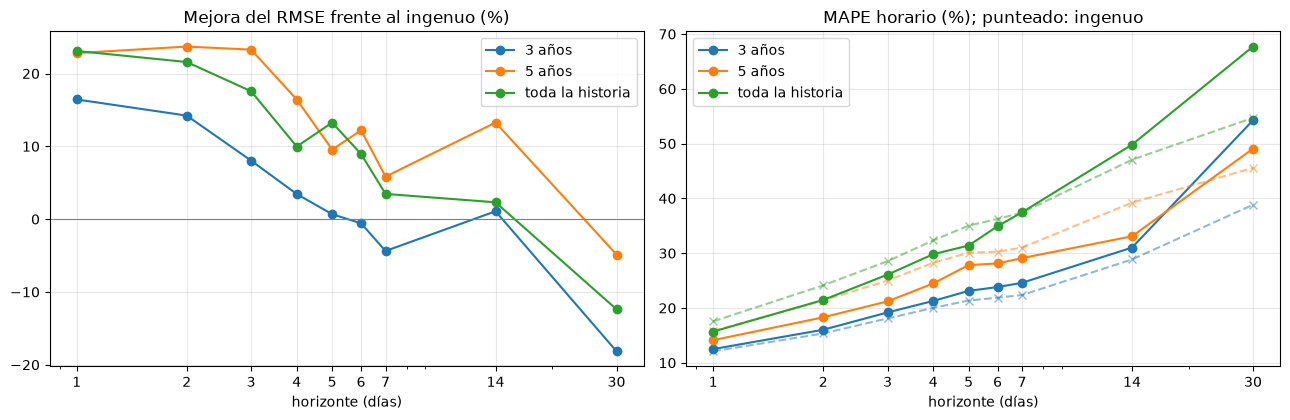

In [9]:
colores = {"3 años": "#1f77b4", "5 años": "#ff7f0e", "toda la historia": "#2ca02c"}
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
for v, g in r.groupby("ventana", sort=False):
    ax[0].plot(g["h"], g["mejora_rmse_pct"], "o-", label=v, color=colores[v])
    ax[1].plot(g["h"], g["mape"], "o-", label=v, color=colores[v])
    ax[1].plot(g["h"], g["mape_ingenuo"], "x--", color=colores[v], alpha=0.5)
ax[0].axhline(0, color="grey", lw=0.8)
ax[0].set(title="Mejora del RMSE frente al ingenuo (%)", xlabel="horizonte (días)", xscale="log")
ax[1].set(title="MAPE horario (%); punteado: ingenuo", xlabel="horizonte (días)", xscale="log")
for a in ax:
    a.set_xticks(HORIZONTES)
    a.set_xticklabels(HORIZONTES)
    a.legend()
fig.tight_layout()
fig.savefig(SALIDA / "mejora_por_horizonte.png", dpi=150)
plt.show()

### Hora por hora

Las dos últimas semanas de la prueba con toda la historia, para h = 1, 7 y 30: el
precio real y el pronosticado en cada hora.

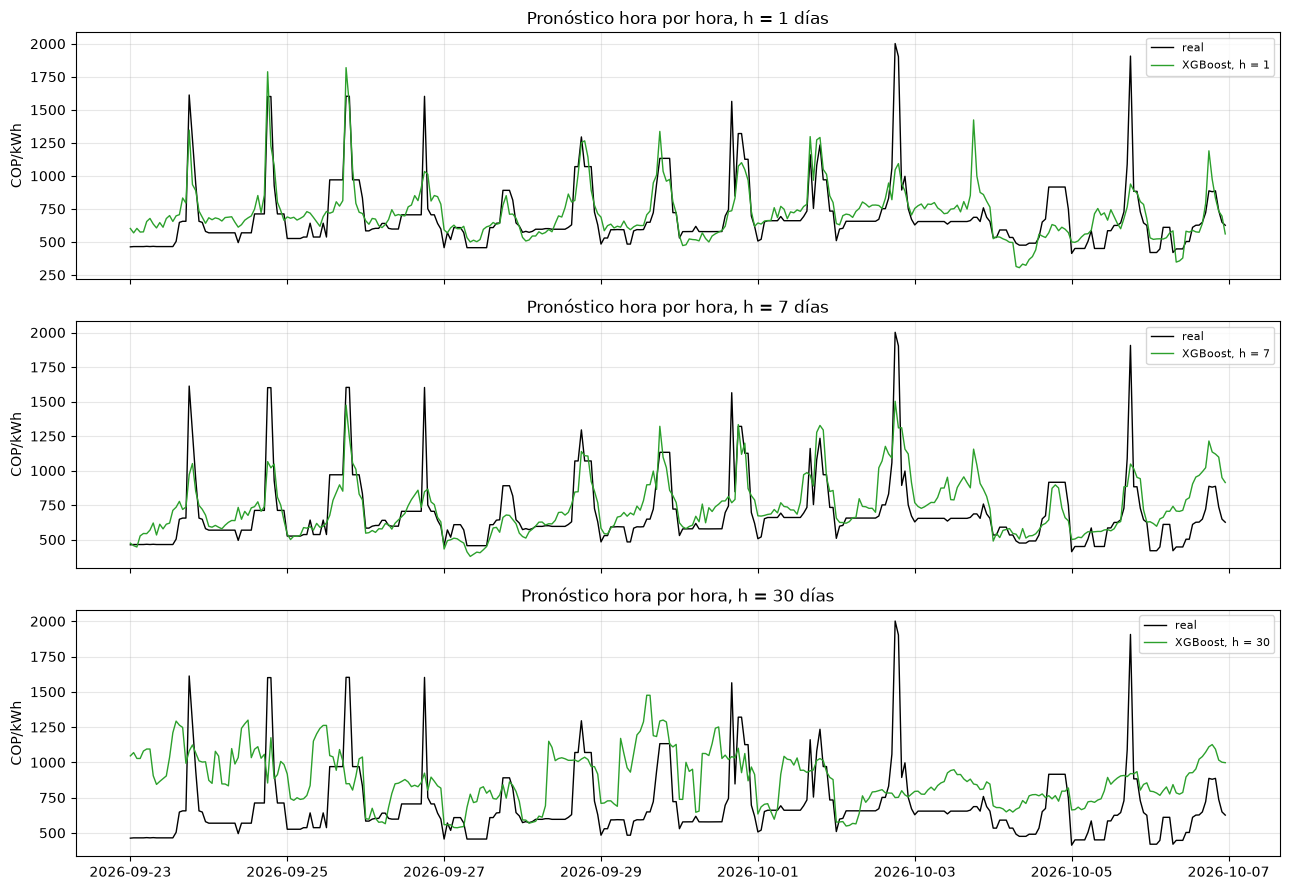

In [10]:
fig, axs = plt.subplots(3, 1, figsize=(13, 9), sharex=True)
base = predicciones[predicciones["ventana"] == "toda la historia"]
fin = base["fecha_objetivo"].max()
for a, h in zip(axs, (1, 7, 30)):
    g = base[(base["h"] == h) & (base["fecha_objetivo"] > fin - pd.Timedelta(days=14))].copy()
    g["momento"] = pd.to_datetime(g["fecha_objetivo"]) + pd.to_timedelta(g["hora"] - 1, unit="h")
    g = g.sort_values("momento")
    a.plot(g["momento"], g["precio_real"], color="black", lw=1, label="real")
    a.plot(g["momento"], g["precio_pron"], color="#2ca02c", lw=1, label=f"XGBoost, h = {h}")
    a.set(ylabel="COP/kWh", title=f"Pronóstico hora por hora, h = {h} días")
    a.legend(fontsize=8)
fig.tight_layout()
fig.savefig(SALIDA / "ejemplo_hora_a_hora.png", dpi=150)
plt.show()

### Error por hora del día

Línea continua: XGBoost. Punteada: el ingenuo.

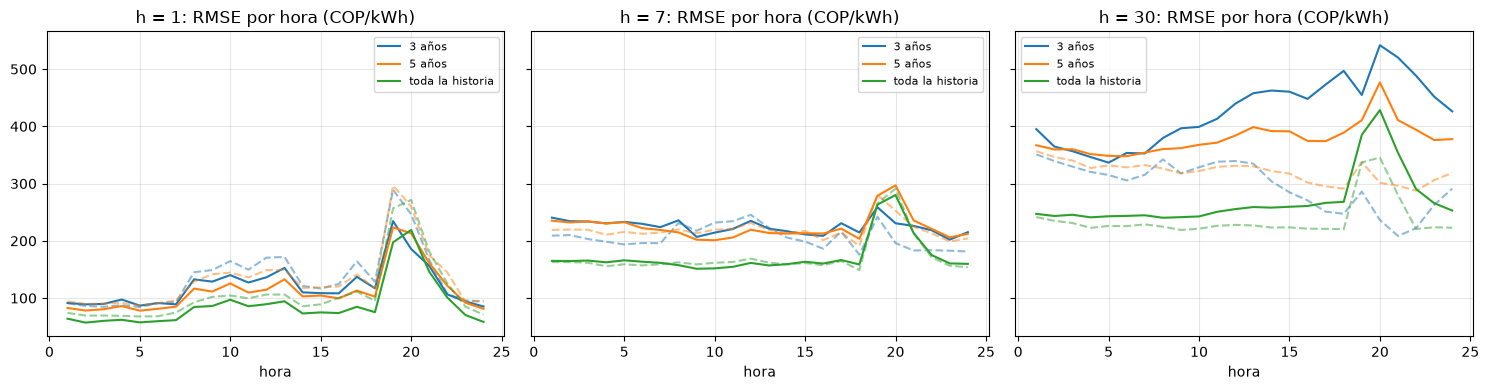

In [11]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for a, h in zip(axs, (1, 7, 30)):
    for v, g in por_hora[por_hora["h"] == h].groupby("ventana", sort=False):
        a.plot(g["hora"], g["rmse_precio"], "-", color=colores[v], label=v)
        a.plot(g["hora"], g["rmse_precio_ingenuo"], "--", color=colores[v], alpha=0.5)
    a.set(title=f"h = {h}: RMSE por hora (COP/kWh)", xlabel="hora")
    a.legend(fontsize=8)
fig.tight_layout()
fig.savefig(SALIDA / "error_por_hora.png", dpi=150)
plt.show()

### Sesgo

El cambio promedio que pronostica el modelo frente al que ocurrió en la prueba.
Un sesgo positivo quiere decir que el precio subió más de lo que el modelo
esperaba.

In [12]:
d = predicciones.assign(e=predicciones["y"] - predicciones["y_hat"])
g = d.groupby(["ventana", "h"], sort=False)
pd.DataFrame({
    "cambio_real_medio": g["y"].mean(),
    "cambio_pronosticado_medio": g["y_hat"].mean(),
    "sesgo": g["e"].mean(),
    "correlacion": g[["y", "y_hat"]].apply(lambda x: x["y"].corr(x["y_hat"])),
}).round(3).unstack("ventana")

cambio_real_medio                         cambio_pronosticado_medio  \
ventana            3 años 5 años toda la historia                    3 años   
h                                                                             
1                   0.002  0.006            0.004                     0.012   
2                   0.004  0.011            0.007                    -0.000   
3                   0.008  0.016            0.010                    -0.019   
4                   0.009  0.020            0.014                    -0.057   
5                   0.011  0.026            0.016                    -0.056   
6                   0.011  0.032            0.019                    -0.049   
7                   0.012  0.036            0.022                    -0.034   
14                  0.002  0.067            0.038                     0.019   
30                 -0.064  0.160            0.075                     0.161   

                                 sesgo                         correlacion  \
ventana 5 años toda la historia 3 años 5 años toda la historia      3 años   
h                                                                            
1        0.026            0.042 -0.011 -0.020           -0.039       0.607   
2        0.002            0.059  0.005  0.009           -0.052       0.591   
3        0.013            0.060  0.028  0.003           -0.049       0.510   
4       -0.044           -0.018  0.067  0.065            0.032       0.466   
5       -0.092           -0.000  0.067  0.118            0.017       0.416   
6       -0.054            0.004  0.060  0.086            0.015       0.400   
7       -0.101           -0.006  0.046  0.137            0.029       0.292   
14      -0.038            0.035 -0.017  0.105            0.003       0.379   
30      -0.050           -0.002 -0.225  0.211            0.077       0.260   

                                 
ventana 5 años toda la historia  
h                                
1        0.665            0.659  
2        0.661            0.643  
3        0.646            0.594  
4        0.578            0.493  
5        0.535            0.504  
6        0.538            0.431  
7        0.487            0.331  
14       0.528            0.318  
30       0.269            0.134

### Qué usa el modelo

Las cinco características con más ganancia en el último modelo de cada prueba
(toda la historia).

In [13]:
top = (importancias[importancias["ventana"] == "toda la historia"]
       .sort_values("ganancia", ascending=False).groupby("h").head(5))
top.assign(ganancia=(100 * top["ganancia"]).round(1)).pivot_table(
    index="h", columns=top.groupby("h").cumcount() + 1, values="columna", aggfunc="first")

,1,2,3,4,5
h,,,,,
1,dlp_dia,dia_semana_h1,dlp_ultima,cmg_despacho_manana,dlp_l6d
2,dlp_dia,dia_semana_h2,es_festivo_h2,es_festivo,dlp_l5d
3,es_festivo_h3,dia_semana_h3,dlp_dia,dlp_l4d,es_festivo
4,es_festivo_h4,dlp_l3d,dlp_dia,dia_semana_h4,lp
5,dlp_l2d,dlp_dia,lp,dia_semana,dia_semana_h5
6,lp,dlp_l1d,dlp_l7d,dlp_dia,aportes_pct_l0d
7,dlp_l7d,lp,aportes_pct_l0d,mes,dlp_l2h
14,dlp_l7d,lp,mes,dlp_l18h,cmg_redespacho_ma30d
30,lp,mes,dlp_l28d,dlp_l20h,aportes_pct_l0d


---
## 7. Lo que se ve

Esto describe la corrida del 10 de octubre de 2026. Si se cambian las ventanas, los
horizontes o la rejilla, hay que releerlo con las tablas de arriba.

1. **Con 3 años no alcanza.** La mejora es menor en todos los horizontes y el MAPE
   queda peor que el del ingenuo incluso en h = 1. Con 5 años o con toda la
   historia, XGBoost le gana al ingenuo de forma significativa hasta h = 4
   (5 años) y h = 6 (toda la historia).
2. **El horizonte útil es de una a dos semanas.** En h = 7 la mejora ya no es
   significativa; en h = 14 solo lo es con 5 años. En h = 30 el modelo es peor
   que el ingenuo en las tres ventanas.
3. **En h = 3**, el pronóstico realista de mañana (el precio se publica con dos
   días de atraso), la mejora es de 18% a 23% con 5 años o más.
4. **Sesgo en horizontes largos.** De h = 4 a h = 7, con 3 y 5 años, el modelo
   pronostica en promedio bajadas de 3% a 10%. En la prueba (2026) el precio
   subió en promedio, así que la reversión a la media que aprendió no se cumplió.
5. **Por hora**, el error más grande está en el pico de la noche (horas 19 a 21),
   también para el ingenuo. En h = 1 la mejora está sobre todo en las horas del
   día; en la madrugada el modelo y el ingenuo quedan parecidos.

**Cuidados al leerlo:**
- **Las tres pruebas son periodos distintos** (cada ventana con su propio corte).
  Los errores absolutos no se comparan entre ventanas; lo comparable es la mejora
  frente al ingenuo dentro de cada prueba.
- **La prueba de 3 años tiene 109 días.** Con tan pocos días, y con horizontes de
  14 o 30 que se traslapan, Diebold-Mariano tiene poca potencia.
- **Las características se eligieron con 2015-2019**, antes de todas las pruebas,
  así que no hay fuga.
- **La rejilla de hiperparámetros es pequeña** (6 configuraciones).